# Kamień–papier–nożyce na UNIHIKER K10: trening BEZ własnych zdjęć

Ta wersja nie potrzebuje zdjęć z kamery K10. Zamiast tego **przerabia gotowy zbiór z Kaggle**,
żeby wyglądał jak obraz z płytki:

1. **Wycina dłonie z zielonego tła** (green screen, progowanie koloru w HSV).
2. **Wkleja je na losowe tła:** zdjęcia (fragmenty zdjęć kwiatów/roślin z TensorFlow,
   opcjonalnie Twój własny folder z tłami) i tła generowane (ściana + biurko, gradienty,
   rozmyte przedmioty, tkaniny).
3. **Ustawia dłoń jak przed kamerą K10:** ręka wchodzi do kadru od dołu (czasem z boku),
   ma różny rozmiar, położenie i obrót.
4. **Udaje kamerę K10:** balans bieli, gamma, ekspozycja, rozmycie, szum, zmniejszenie
   240→96 przez uśrednianie bloków (jak na płytce) i redukcja kolorów do RGB565.

Dalej wszystko jest jak w zwykłym notebooku: MobileNetV2 0.35, 96×96, kwantyzacja INT8 i plik `model_data.h`.

**Kaggle:**
- Settings → *Internet: On* (wagi ImageNet i zdjęcia na tła),
- dodaj dataset `drgfreeman/rockpaperscissors` (Add Input),
- GPU T4 przyspiesza trening, ale nie jest wymagane.

In [1]:
import os, sys, glob, math, random, subprocess, importlib
import numpy as np
print("NumPy", np.__version__)

# Na Kaggle zdarza się, że preinstalowany OpenCV jest skompilowany pod NumPy 2.x, a środowisko ma
# NumPy 1.x (błąd "numpy._core.multiarray failed to import"). Wtedy doinstalowujemy obok wersję
# OpenCV zgodną z obiema wersjami NumPy, bez ruszania NumPy ani TensorFlow.
def importuj_cv2():
    try:
        import cv2
        return cv2
    except ImportError as e:
        print("OpenCV nie pasuje do tej wersji NumPy:", e)
        print("Instaluję zgodny OpenCV (opencv-python-headless 4.10.0.84) do /tmp/cv2fix ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                        "--target", "/tmp/cv2fix", "opencv-python-headless==4.10.0.84"], check=True)
        for m in [m for m in list(sys.modules) if m == "cv2" or m.startswith("cv2.")]:
            del sys.modules[m]
        sys.path.insert(0, "/tmp/cv2fix")
        importlib.invalidate_caches()
        import cv2
        return cv2

cv2 = importuj_cv2()
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| OpenCV", cv2.__version__)

NumPy 2.4.6
TensorFlow 2.21.0 | Keras 3.13.2 | OpenCV 4.14.0


## 0. Google Colab: zapis na Dysku Google

Ta komórka działa tylko w Colabie (na Kaggle i w lokalnym Jupyterze nic nie robi). Podłącza Twój
Dysk Google i używa folderu **`Mój dysk/K10`**, który przetrwa zamknięcie środowiska:

- **Zbiór danych:**
  - przy pierwszym uruchomieniu notebook pobiera go z Kaggle i zapisuje na Dysku jako `K10/rockpaperscissors.zip`,
  - przy kolejnych rozpakowuje go z Dysku (zamiast pobierać), co trwa kilkanaście sekund,
  - jeśli wolisz, wgraj na Dysk do `K10/` własny ZIP albo folder `rps-cv-images` (z `paper/`, `rock/`, `scissors/`), a notebook użyje go zamiast pobierania.
- **Wyniki:** `model_data.h`, `rps_int8.tflite` i wytrenowany model `model.keras` lądują w `K10/wyniki/`.

**GPU:** *Środowisko wykonawcze → Zmień typ środowiska wykonawczego → T4 GPU*.

In [2]:
import shutil
W_COLAB = "google.colab" in sys.modules
DANE_COLAB = OUT_DIR_COLAB = None
KLASY_ZBIORU = ("paper", "rock", "scissors")

def folder_z_klasami(baza):
    for root, dirs, _ in os.walk(baza):
        dirs[:] = [d for d in dirs if not d.startswith(".")]
        if all(os.path.isdir(os.path.join(root, c)) for c in KLASY_ZBIORU):
            return root
    return None

if W_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJEKT = "/content/drive/MyDrive/K10"
    os.makedirs(PROJEKT, exist_ok=True)
    OUT_DIR_COLAB = os.path.join(PROJEKT, "wyniki")
    os.makedirs(OUT_DIR_COLAB, exist_ok=True)
    DANE = "/content/dane"                         # szybki dysk lokalny Colaba

    juz_rozpakowane = os.path.isdir(DANE) and folder_z_klasami(DANE)
    if not juz_rozpakowane:
        zipy = sorted(glob.glob(os.path.join(PROJEKT, "*.zip")))
        folder_na_dysku = folder_z_klasami(PROJEKT)
        if zipy:
            print("Rozpakowuję z Dysku:", zipy[0])
            shutil.unpack_archive(zipy[0], DANE)
        elif folder_na_dysku:
            print("Kopiuję zbiór z Dysku:", folder_na_dysku)
            shutil.copytree(folder_na_dysku, os.path.join(DANE, "rps-cv-images"))
        else:
            print("Pierwsze uruchomienie: pobieram zbiór z Kaggle...")
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
            pobrane = kagglehub.dataset_download("drgfreeman/rockpaperscissors")
            shutil.copytree(pobrane, DANE, dirs_exist_ok=True)
            shutil.make_archive(os.path.join(PROJEKT, "rockpaperscissors"), "zip", pobrane)
            print("Zapisano kopię na Dysku: K10/rockpaperscissors.zip")

    DANE_COLAB = folder_z_klasami(DANE)
    print("Colab: zbiór =", DANE_COLAB, "| wyniki =", OUT_DIR_COLAB)
else:
    print("To nie jest Colab: pomijam Dysk Google.")

Mounted at /content/drive
Rozpakowuję z Dysku: /content/drive/MyDrive/K10/rockpaperscissors.zip
Colab: zbiór = /content/dane | wyniki = /content/drive/MyDrive/K10/wyniki


## 1. Ustawienia

In [3]:
IMG = 96                 # wejście modelu (musi się zgadzać z MODEL_IMG na K10)
KADR = 240               # K10 wycina z kamery kwadrat 240x240 i zmniejsza go do 96x96
ALPHA = 0.35
BATCH = 32
EPOCHS_HEAD = 12
EPOCHS_FINE = 10
ODMROZONE_WARSTWY = 40   # ile końcowych warstw MobileNetV2 dostrajać w etapie 2
LR_FINE = 1e-4           # tempo uczenia w etapie 2
CIERPLIWOSC = 2          # EarlyStopping: ile epok bez poprawy, zanim trening się zatrzyma
KLASY_DLONI = ["paper", "rock", "scissors"]   # foldery w zbiorze z Kaggle
KLASA_BRAK = True        # dodatkowa klasa "none" = kadr BEZ dłoni (same tła); wtedy K10 nie zgaduje na pustym ekranie
CLASSES = KLASY_DLONI + (["none"] if KLASA_BRAK else [])   # kolejność = kolejność etykiet na K10

# Folder, w którym są podfoldery paper/, rock/, scissors/.
# Na Kaggle: "/kaggle/input/rockpaperscissors/rps-cv-images".
# W lokalnym Jupyterze: ścieżka WZGLĘDEM FOLDERU NOTEBOOKA albo pełna ścieżka na dysku.
# Uwaga: "Copy Path" w JupyterLab daje ścieżkę względem folderu startowego Jupytera, nie notebooka.
# Jeśli ścieżka jest zła, notebook sam poszuka folderu z paper/rock/scissors w pobliżu.
KAGGLE_DIR = DANE_COLAB or "/kaggle/input/rockpaperscissors/rps-cv-images"
WARIANTY_NA_DLON = 4     # ile sztucznych zdjęć z jednej dłoni na JEDNĄ epokę (sceny są losowane od nowa co epokę)
ROZMIAR_DLONI = 160      # dłuższy bok przechowywanej wyciętej dłoni (mniej = mniej RAM)
LICZBA_ZDJEC_TLA = 300   # ile zdjęć na tła trzymać w pamięci (mniej = mniej RAM)
CZESC_WALIDACJI = 0.15   # walidacja na dłoniach, których model nie widział w treningu
POBIERZ_ZDJECIA_TLA = True   # fragmenty zdjęć z flower_photos (TensorFlow) jako realistyczne tła
TLA_WNETRZA = "stepanyarullin/interior-design-styles"   # zbiór z Kaggle ze zdjęciami wnętrz ("" = wyłącz)
ZDJEC_NA_STYL = 15       # ile zdjęć wnętrz brać z każdej klasy (stylu) tego zbioru
BG_DIR = ""              # opcjonalnie: własny folder ze zdjęciami na tła (np. dataset wnętrz z Kaggle)
K10_TEST_DIR = ""        # opcjonalnie: kilka zdjęć z K10 (paper/rock/scissors) TYLKO do sprawdzenia modelu
SEED = 42
OUT_DIR = OUT_DIR_COLAB or ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".")

def ma_klasy(folder):
    return all(os.path.isdir(os.path.join(folder, c)) for c in KLASY_DLONI)

def znajdz_zbior(sciezka, max_glebokosc=6):
    kandydaci = [sciezka, sciezka.lstrip("/"), os.path.join(os.getcwd(), sciezka.lstrip("/"))]
    for k in kandydaci:
        if k and ma_klasy(k):
            return os.path.abspath(k)
    print(f"Nie ma folderu {sciezka!r} (bieżący folder: {os.getcwd()}). Szukam zbioru w pobliżu...")
    for baza in [os.getcwd(), os.path.dirname(os.getcwd()), os.path.expanduser("~"), "/kaggle/input"]:
        if not os.path.isdir(baza):
            continue
        for root, dirs, _ in os.walk(baza):
            dirs[:] = [d for d in dirs if not d.startswith(".") and d not in ("site-packages", "node_modules", "drive")]
            if root[len(baza):].count(os.sep) >= max_glebokosc:
                dirs[:] = []
            if ma_klasy(root):
                return os.path.abspath(root)
    raise FileNotFoundError("Nie znalazłam folderu z podfolderami paper/, rock/, scissors/. "
                            "Wpisz pełną ścieżkę w KAGGLE_DIR.")

KAGGLE_DIR = znajdz_zbior(KAGGLE_DIR)
print("Zbiór:", KAGGLE_DIR)
for c in KLASY_DLONI:
    print(f"  {c}: {len(os.listdir(os.path.join(KAGGLE_DIR, c)))} plików")

rng = np.random.default_rng(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

Zbiór: /content/dane
  paper: 712 plików
  rock: 726 plików
  scissors: 750 plików


## 2. Wycinanie dłoni z zielonego tła

Tło to piksele o zielonym odcieniu, wystarczającym nasyceniu i jasności. Z maski zostawiamy
tylko duże fragmenty (dłoń z ręką) i lekko wygładzamy krawędź. Zielona poświata na brzegach
dłoni jest usuwana (*despill*). Na koniec każdą dłoń obracamy tak, żeby ręka wchodziła od dołu.

In [4]:
H_MIN, H_MAX = 35, 95    # zakres odcienia zieleni w OpenCV (0–180)
S_MIN, V_MIN = 60, 30

def wytnij_dlon(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    tlo = (h >= H_MIN) & (h <= H_MAX) & (s >= S_MIN) & (v >= V_MIN)
    maska = (~tlo).astype(np.uint8) * 255
    maska = cv2.morphologyEx(maska, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    maska = cv2.morphologyEx(maska, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    # zostaw tylko duże spójne fragmenty (usuwa drobinki i szum)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(maska, 8)
    if n <= 1:
        return None
    najw = stats[1:, cv2.CC_STAT_AREA].max()
    keep = np.zeros_like(maska)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= 0.15 * najw:
            keep[lab == i] = 255
    if keep.sum() / 255 < 0.03 * keep.size:      # prawie nic nie zostało -> pomiń
        return None
    alfa = cv2.GaussianBlur(keep, (3, 3), 0)

    # despill: na dłoni zielony kanał nie może być mocniejszy niż max(R, B)
    b, g, r = cv2.split(bgr.astype(np.int16))
    g = np.minimum(g, np.maximum(r, b))
    rgb = cv2.merge([r, g, b]).clip(0, 255).astype(np.uint8)

    # obróć tak, żeby ręka (krawędź z największą liczbą pikseli dłoni) była na dole
    krawedzie = [keep[0, :].sum(), keep[:, -1].sum(), keep[-1, :].sum(), keep[:, 0].sum()]  # góra, prawo, dół, lewo
    k = {0: 2, 1: 3, 2: 0, 3: 1}[int(np.argmax(krawedzie))]    # liczba obrotów o 90° w lewo
    rgba = np.dstack([rgb, alfa])
    rgba = np.ascontiguousarray(np.rot90(rgba, k))

    ys, xs = np.where(rgba[..., 3] > 0)
    rgba = rgba[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    skala = ROZMIAR_DLONI / max(rgba.shape[:2])              # mały rozmiar = mało RAM-u
    if skala < 1:
        rgba = cv2.resize(rgba, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    return rgba

dlonie = {c: [] for c in KLASY_DLONI}
for c in KLASY_DLONI:
    pliki = sorted(glob.glob(os.path.join(KAGGLE_DIR, c, "*")))
    wczytane = 0
    for p in pliki:
        img = cv2.imread(p)
        if img is None:
            continue
        wczytane += 1
        cut = wytnij_dlon(img)
        if cut is not None:
            dlonie[c].append(cut)
    print(f"{c}: plików {len(pliki)}, wczytanych obrazów {wczytane}, wycięto {len(dlonie[c])} dłoni")

if min(len(v) for v in dlonie.values()) == 0:
    raise RuntimeError("Dla którejś klasy nie wycięto żadnej dłoni. Jeśli 'plików' = 0, popraw KAGGLE_DIR. "
                       "Jeśli pliki są, a wycięto 0, zmień progi H_MIN/H_MAX/S_MIN/V_MIN.")

paper: plików 712, wczytanych obrazów 712, wycięto 712 dłoni
rock: plików 726, wczytanych obrazów 726, wycięto 726 dłoni
scissors: plików 750, wczytanych obrazów 750, wycięto 750 dłoni


Podgląd wycinania: czarne tło = to, co zostało uznane za tło.

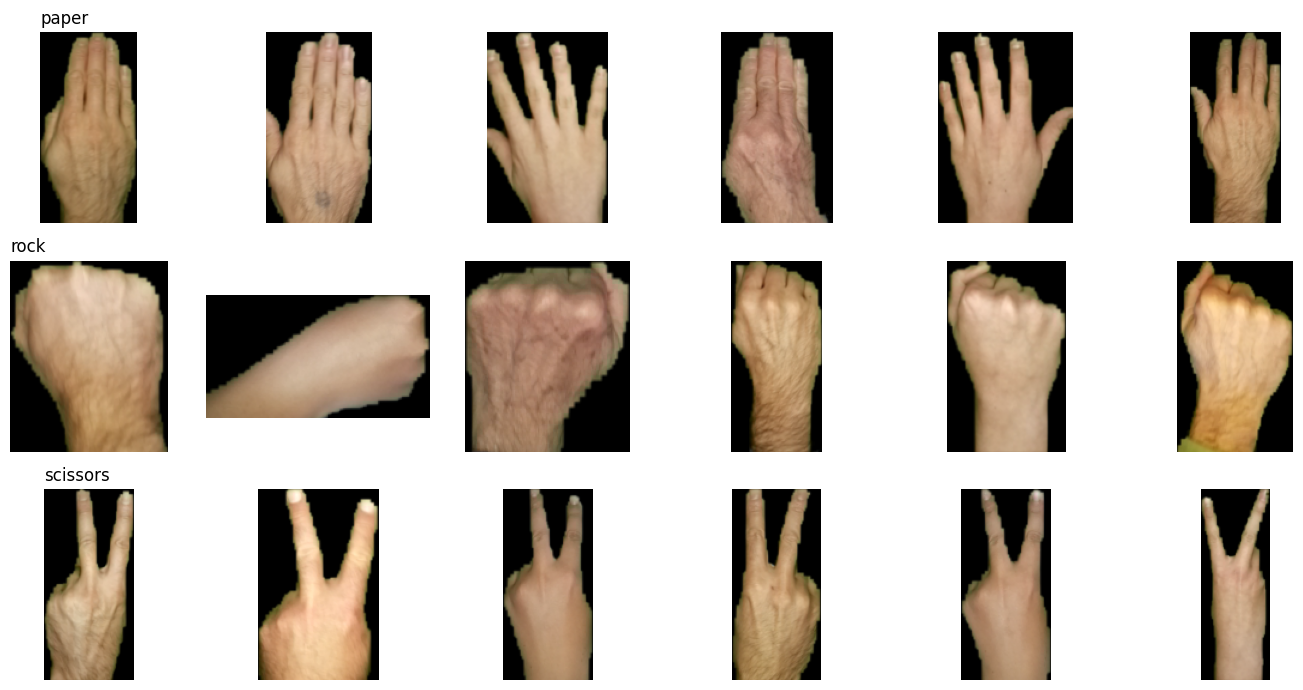

In [5]:
fig, ax = plt.subplots(3, 6, figsize=(14, 7))
for r, c in enumerate(KLASY_DLONI):
    for j in range(6):
        cut = dlonie[c][rng.integers(len(dlonie[c]))]
        pod = (cut[..., :3].astype(np.float32) * (cut[..., 3:] / 255.0)).astype(np.uint8)
        ax[r, j].imshow(pod); ax[r, j].axis("off")
    ax[r, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 3. Tła

Mieszamy cztery źródła:
- **zdjęcia wnętrz** ze zbioru Kaggle [`interior-design-styles`](https://www.kaggle.com/datasets/stepanyarullin/interior-design-styles),
  po `ZDJEC_NA_STYL` (15) losowych zdjęć z każdego stylu. To najbardziej realistyczne tło, bo tak wygląda pokój za Twoją dłonią.
  Wybrane zdjęcia są zapisywane w folderze `tla_wnetrza` (w Colabie na Dysku: `K10/tla_wnetrza`),
  więc cały zbiór pobiera się tylko raz,
- **fragmenty zdjęć** `flower_photos` z TensorFlow (liście, niebo, ziemia),
- **Twój folder `BG_DIR`**, jeśli go podasz,
- **tła generowane**: ściana + blat, gradienty, rozmyte przedmioty, tkaniny.

In [6]:
def lista_zdjec(folder):
    ext = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")
    return [p for e in ext for p in glob.glob(os.path.join(folder, "**", e), recursive=True)]

zdjecia_tla = []
if POBIERZ_ZDJECIA_TLA:
    try:
        p = keras.utils.get_file(
            "flower_photos.tgz",
            "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
            extract=True)
        zdjecia_tla += [f for f in lista_zdjec(os.path.dirname(p)) if "flower_photos" in f]
    except Exception as e:
        print("Nie udało się pobrać zdjęć na tła (zostają tła generowane):", e)
if BG_DIR and os.path.isdir(BG_DIR):
    zdjecia_tla += lista_zdjec(BG_DIR)
print("Zdjęć dostępnych jako tła:", len(zdjecia_tla))

# ---- zdjęcia wnętrz: po ZDJEC_NA_STYL z każdego stylu, zapisane na stałe w folderze tla_wnetrza ----
FOLDER_WNETRZ = os.path.join(PROJEKT if W_COLAB else OUT_DIR, "tla_wnetrza")

def pobierz_wnetrza():
    os.makedirs(FOLDER_WNETRZ, exist_ok=True)
    # na Kaggle zbiór może być dodany jako Input; wszędzie indziej pobieramy go przez kagglehub
    kandydaci = [d for d in glob.glob("/kaggle/input/*") if "interior" in d.lower()]
    if kandydaci:
        zrodlo = kandydaci[0]
    else:
        try:
            import kagglehub
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        print("Pobieram zbiór wnętrz z Kaggle (jednorazowo, może potrwać kilka minut)...")
        zrodlo = kagglehub.dataset_download(TLA_WNETRZA)
    # klasa = nazwa folderu, w którym leży zdjęcie (train/test z tymi samymi stylami są łączone)
    style = {}
    for f in lista_zdjec(zrodlo):
        style.setdefault(os.path.basename(os.path.dirname(f)).lower(), []).append(f)
    los = random.Random(SEED)
    for styl, pliki in sorted(style.items()):
        for i, f in enumerate(los.sample(sorted(pliki), min(ZDJEC_NA_STYL, len(pliki)))):
            shutil.copy(f, os.path.join(FOLDER_WNETRZ, f"{styl}_{i:02d}{os.path.splitext(f)[1].lower()}"))
    print(f"Wybrano zdjęcia wnętrz z {len(style)} stylów: {', '.join(sorted(style))}")

zdjecia_wnetrz = []
if TLA_WNETRZA:
    if not lista_zdjec(FOLDER_WNETRZ):
        try:
            pobierz_wnetrza()
        except Exception as e:
            print("Nie udało się pobrać zdjęć wnętrz (zostają pozostałe tła):", e)
            print("Jeśli to błąd logowania: w Colabie dodaj sekrety KAGGLE_USERNAME i KAGGLE_KEY "
                  "(ikona klucza po lewej), na Kaggle dodaj zbiór przez Add Input.")
    else:
        print("Zdjęcia wnętrz już są w", FOLDER_WNETRZ)
    zdjecia_wnetrz = lista_zdjec(FOLDER_WNETRZ)
print("Zdjęć wnętrz:", len(zdjecia_wnetrz))

# wczytujemy zdjęcia do pamięci (pomniejszone), żeby nie czytać dysku w kółko
def wczytaj(lista):
    out = []
    for p in lista:
        im = cv2.imread(p)
        if im is None or min(im.shape[:2]) < 64:
            continue
        s = 260 / min(im.shape[:2])
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        out.append(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    return out

cache_wnetrz = wczytaj(zdjecia_wnetrz)
cache_tla = wczytaj(random.sample(zdjecia_tla, min(LICZBA_ZDJEC_TLA, len(zdjecia_tla))))
print(f"W pamięci: {len(cache_wnetrz)} zdjęć wnętrz, {len(cache_tla)} innych zdjęć")

def losowy_kolor():
    # przewaga stonowanych barw, jak we wnętrzach
    base = rng.uniform(40, 230)
    return np.clip(base + rng.normal(0, 35, 3), 0, 255)

def tlo_zdjecie(cache):
    im = cache[rng.integers(len(cache))]
    s = rng.uniform(KADR, min(im.shape[:2]))
    y = rng.integers(0, im.shape[0] - int(s) + 1)
    x = rng.integers(0, im.shape[1] - int(s) + 1)
    crop = im[y:y + int(s), x:x + int(s)]
    out = cv2.resize(crop, (KADR, KADR), interpolation=cv2.INTER_AREA)
    if rng.random() < 0.5:
        out = cv2.GaussianBlur(out, (0, 0), rng.uniform(0.5, 3.0))  # tło poza ostrością
    return out

def tlo_generowane():
    t = rng.integers(5)
    yy, xx = np.mgrid[0:KADR, 0:KADR].astype(np.float32) / KADR
    if t == 0:      # ściana + blat
        horyzont = rng.uniform(0.3, 0.8)
        a, b = losowy_kolor(), losowy_kolor()
        out = np.where((yy > horyzont)[..., None], b, a).astype(np.float32)
        out += rng.normal(0, 6, out.shape)
    elif t == 1:    # gradient
        a, b = losowy_kolor(), losowy_kolor()
        kat = rng.uniform(0, 2 * np.pi)
        w = np.clip((xx * np.cos(kat) + yy * np.sin(kat) + 1) / 2, 0, 1)[..., None]
        out = a * (1 - w) + b * w
    elif t == 2:    # rozmyte przedmioty
        out = np.full((KADR, KADR, 3), losowy_kolor(), np.float32)
        for _ in range(rng.integers(3, 9)):
            c = tuple(float(v) for v in losowy_kolor())
            if rng.random() < 0.5:
                cv2.ellipse(out, (int(rng.integers(KADR)), int(rng.integers(KADR))),
                            (int(rng.integers(15, 90)), int(rng.integers(15, 90))),
                            float(rng.uniform(0, 180)), 0, 360, c, -1)
            else:
                x0, y0 = rng.integers(-40, KADR, 2)
                cv2.rectangle(out, (int(x0), int(y0)), (int(x0 + rng.integers(20, 140)), int(y0 + rng.integers(20, 140))), c, -1)
        out = cv2.GaussianBlur(out, (0, 0), rng.uniform(2, 7))
    elif t == 3:    # tkanina / paski
        a, b = losowy_kolor(), losowy_kolor()
        f = rng.uniform(4, 25)
        kat = rng.uniform(0, np.pi)
        w = (np.sin((xx * np.cos(kat) + yy * np.sin(kat)) * f * 2 * np.pi) + 1) / 2
        out = a * (1 - w[..., None]) + b * w[..., None]
        out += rng.normal(0, 8, out.shape)
    else:           # plamy o niskiej częstotliwości
        n = int(rng.integers(3, 10))
        out = cv2.resize(rng.uniform(30, 230, (n, n, 3)).astype(np.float32), (KADR, KADR),
                         interpolation=cv2.INTER_CUBIC)
    return np.clip(out, 0, 255).astype(np.uint8)

def losowe_tlo():
    r = rng.random()
    if cache_wnetrz and r < 0.5:          # 50% wnętrza
        return tlo_zdjecie(cache_wnetrz)
    if cache_tla and r < 0.75:            # 25% inne zdjęcia
        return tlo_zdjecie(cache_tla)
    return tlo_generowane()               # reszta: tła generowane

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Zdjęć dostępnych jako tła: 3670
Zdjęcia wnętrz już są w /content/drive/MyDrive/K10/tla_wnetrza
Zdjęć wnętrz: 950
W pamięci: 950 zdjęć wnętrz, 300 innych zdjęć


## 4. Składanie sceny i udawanie kamery K10

In [7]:
def obroc(rgba, kat):
    h, w = rgba.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), kat, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    out = cv2.warpAffine(rgba, M, (nw, nh), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0, 0))
    ys, xs = np.where(out[..., 3] > 8)
    return out[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def wklej(tlo, rgba, x, y):
    """Wkleja rgba w tło z lewym górnym rogiem w (x, y); fragmenty poza kadrem są obcinane."""
    H, W = tlo.shape[:2]
    h, w = rgba.shape[:2]
    x0, y0, x1, y1 = max(x, 0), max(y, 0), min(x + w, W), min(y + h, H)
    if x1 <= x0 or y1 <= y0:
        return tlo
    fg = rgba[y0 - y:y1 - y, x0 - x:x1 - x]
    a = fg[..., 3:4].astype(np.float32) / 255.0
    out = tlo.astype(np.float32)
    out[y0:y1, x0:x1] = out[y0:y1, x0:x1] * (1 - a) + fg[..., :3] * a
    return out

def scena(dlon):
    tlo = losowe_tlo()
    if dlon is None:                                  # klasa "none": sam kadr bez dłoni
        return tlo.astype(np.float32)
    d = dlon
    if rng.random() < 0.5:
        d = d[:, ::-1]                                # lewa / prawa ręka
    # kierunek wejścia ręki: najczęściej od dołu, czasem z boku lub z góry
    k = rng.choice([0, 1, 3, 2], p=[0.7, 0.12, 0.12, 0.06])
    d = np.ascontiguousarray(np.rot90(d, k))
    d = obroc(d, rng.uniform(-30, 30))

    # Rozmiar i położenie tak, żeby PALCE zawsze były w kadrze (inaczej papier i nożyce
    # stają się nie do odróżnienia, a model uczy się na błędnych przykładach).
    # Poza kadr może wyjść tylko ręka po stronie, z której wchodzi (do 25% długości).
    wysun = rng.uniform(0.0, 0.25)
    dl_os = d.shape[0] if k in (0, 2) else d.shape[1]     # wymiar wzdłuż ręki
    dl_po = d.shape[1] if k in (0, 2) else d.shape[0]     # wymiar w poprzek
    s_max = min(0.95 * KADR / ((1 - wysun) * dl_os), 0.95 * KADR / dl_po)
    s = rng.uniform(0.6, 1.0) * s_max                     # widoczna dłoń: ~55–95% kadru
    d = cv2.resize(d, None, fx=s, fy=s, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    h, w = d.shape[:2]
    po = h if k in (1, 3) else w
    poz = rng.uniform(0, max(1.0, KADR - po))             # w poprzek: cała dłoń w kadrze
    if k == 0:   x, y = int(poz), int(KADR - h + wysun * h)          # od dołu
    elif k == 2: x, y = int(poz), int(-wysun * h)                     # od góry
    elif k == 1: x, y = int(KADR - w + wysun * w), int(poz)          # z prawej
    else:        x, y = int(-wysun * w), int(poz)                     # z lewej
    return wklej(tlo, d, x, y)

def udawaj_k10(img):
    """img: float32 RGB 240x240 -> uint8 RGB 96x96, jak po przetworzeniu na płytce."""
    x = img / 255.0
    x = x * rng.uniform(0.8, 1.2, 3)                        # balans bieli
    x = np.clip(x * rng.uniform(0.55, 1.35), 0, 1)          # ekspozycja
    x = x ** rng.uniform(0.7, 1.5)                          # gamma / krzywa sensora
    m = x.mean()
    x = np.clip((x - m) * rng.uniform(0.7, 1.15) + m, 0, 1) # kontrast
    if rng.random() < 0.3:                                  # niższe nasycenie
        g = x.mean(axis=2, keepdims=True)
        x = g + (x - g) * rng.uniform(0.4, 0.9)
    x = (x * 255).astype(np.float32)
    if rng.random() < 0.7:
        x = cv2.GaussianBlur(x, (0, 0), rng.uniform(0.3, 1.2))  # optyka / ostrość
    x = x + rng.normal(0, rng.uniform(1, 9), x.shape)           # szum sensora
    x = np.clip(x, 0, 255).astype(np.uint8)
    x = cv2.resize(x, (IMG, IMG), interpolation=cv2.INTER_AREA)  # uśrednianie bloków, jak w K10
    # redukcja do RGB565 i z powrotem do 8 bitów (r*255/31 itd.), jak na płytce
    r = np.round((x[..., 0] >> 3).astype(np.float32) * 255 / 31)
    g = np.round((x[..., 1] >> 2).astype(np.float32) * 255 / 63)
    b = np.round((x[..., 2] >> 3).astype(np.float32) * 255 / 31)
    return np.stack([r, g, b], -1).astype(np.uint8)

def generuj(lista_dloni, ile_na_dlon):
    X, y = [], []
    for ci, c in enumerate(CLASSES):
        for dlon in lista_dloni[c]:
            for _ in range(ile_na_dlon):
                X.append(udawaj_k10(scena(dlon)))
                y.append(ci)
    X, y = np.array(X), np.array(y)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

# podział na trening / walidację PO DŁONIACH (żeby walidacja była uczciwa)
dlonie_tr, dlonie_val = {}, {}
for c in KLASY_DLONI:
    lst = dlonie[c][:]
    random.shuffle(lst)
    n_val = int(len(lst) * CZESC_WALIDACJI)
    dlonie_val[c], dlonie_tr[c] = lst[:n_val], lst[n_val:]
if KLASA_BRAK:   # "none" dostaje tyle przykładów co przeciętna klasa dłoni (None = scena bez dłoni)
    dlonie_tr["none"] = [None] * (sum(len(dlonie_tr[c]) for c in KLASY_DLONI) // len(KLASY_DLONI))
    dlonie_val["none"] = [None] * (sum(len(dlonie_val[c]) for c in KLASY_DLONI) // len(KLASY_DLONI))

X_val, y_val = generuj(dlonie_val, 3)       # mała, stała walidacja
print("Walidacja:", X_val.shape)

# Trening: sceny składane NA BIEŻĄCO, bez trzymania tysięcy zdjęć w RAM-ie.
# Każda epoka dostaje nowe, losowe sceny (to dodatkowo pomaga modelowi).
pary_tr = [(ci, d) for ci, c in enumerate(CLASSES) for d in dlonie_tr[c]]

def generator_treningu():
    lista = pary_tr[:]
    while True:
        random.shuffle(lista)
        for ci, d in lista:
            yield udawaj_k10(scena(d)), ci

KROKI_NA_EPOKE = len(pary_tr) * WARIANTY_NA_DLON // BATCH
print("Dłoni treningowych:", len(pary_tr), "| kroków na epokę:", KROKI_NA_EPOKE)

Walidacja: (1302, 96, 96, 3)
Dłoni treningowych: 2482 | kroków na epokę: 310


Podgląd: tak mniej więcej model zobaczy obraz z K10. Warto przejrzeć, czy dłonie są dobrze wycięte.

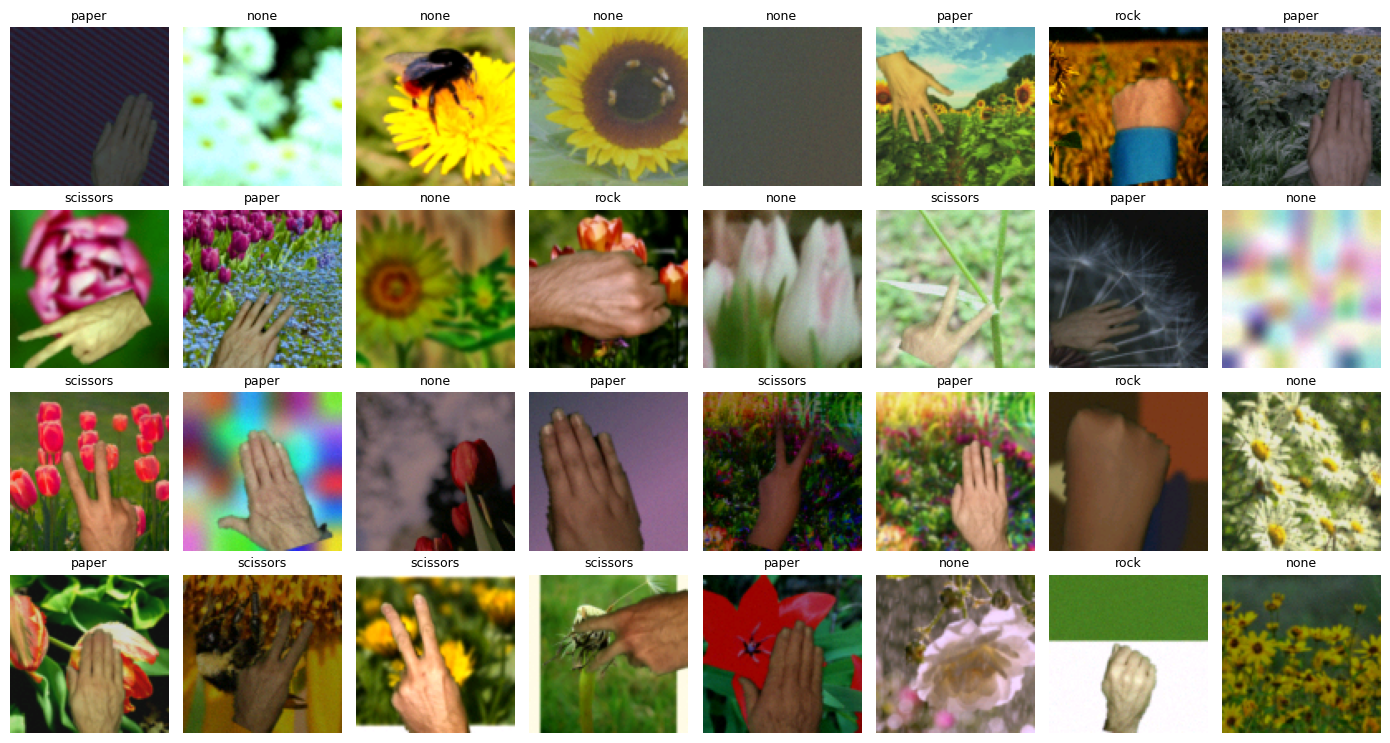

In [ ]:
fig, ax = plt.subplots(4, 8, figsize=(14, 7.5))
for i, a in enumerate(ax.flat):
    ci, d = pary_tr[rng.integers(len(pary_tr))]
    a.imshow(udawaj_k10(scena(d))); a.set_title(CLASSES[ci], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Dane dla Keras (+ lekka augmentacja w locie)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE
onehot = lambda y: tf.one_hot(y, len(CLASSES))

aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom((-0.05, 0.1)),
    layers.RandomTranslation(0.05, 0.05),
])

def przygotuj(x, y):
    return tf.cast(x, tf.float32), onehot(y)

train_aug = (tf.data.Dataset.from_generator(
                 generator_treningu,
                 output_signature=(tf.TensorSpec((IMG, IMG, 3), tf.uint8), tf.TensorSpec((), tf.int32)))
             .map(przygotuj).batch(BATCH)
             .map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
             .prefetch(AUTOTUNE))
val_b = tf.data.Dataset.from_tensor_slices((X_val, y_val)).map(przygotuj).batch(BATCH).prefetch(AUTOTUNE)

## 6. Model (tak samo jak w zwykłym notebooku)

In [9]:
base = keras.applications.MobileNetV2(
    input_shape=(IMG, IMG, 3), alpha=ALPHA, include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input((IMG, IMG, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inputs, outputs)

2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 7. Trening: etap 1 (głowica) i etap 2 (dostrajanie)

In [10]:
cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=CIERPLIWOSC, restore_best_weights=True),
      # najlepszy model zapisywany na bieżąco (w Colabie na Dysku), więc reset kernela nie kasuje treningu
      keras.callbacks.ModelCheckpoint(os.path.join(OUT_DIR, "model.keras"), monitor="val_loss", save_best_only=True)]
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_aug, steps_per_epoch=KROKI_NA_EPOKE, validation_data=val_b, epochs=EPOCHS_HEAD, callbacks=cb)

base.trainable = True
for layer in base.layers[:-ODMROZONE_WARSTWY]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(LR_FINE), loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_aug, steps_per_epoch=KROKI_NA_EPOKE, validation_data=val_b, epochs=EPOCHS_FINE, callbacks=cb)

model.save(os.path.join(OUT_DIR, "model.keras"))   # kopia wytrenowanego modelu (na Colabie: na Dysku)
print("Zapisano model.keras w", OUT_DIR)

Epoch 1/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 246s 745ms/step - accuracy: 0.7139 - loss: 0.7310 - val_accuracy: 0.8088 - val_loss: 0.4907
Epoch 2/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 212s 686ms/step - accuracy: 0.8005 - loss: 0.5325 - val_accuracy: 0.8241 - val_loss: 0.4708
Epoch 3/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 213s 689ms/step - accuracy: 0.8127 - loss: 0.5081 - val_accuracy: 0.8472 - val_loss: 0.4096
Epoch 4/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 210s 681ms/step - accuracy: 0.8225 - loss: 0.4813 - val_accuracy: 0.8548 - val_loss: 0.3833
Epoch 5/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 216s 699ms/step - accuracy: 0.8190 - loss: 0.4826 - val_accuracy: 0.8310 - val_loss: 0.4162
Epoch 6/12
310/310 ━━━━━━━━━━━━━━━━━━━━ 215s 694ms/step - accuracy: 0.8276 - loss: 0.4588 - val_accuracy: 0.8379 - val_loss: 0.4256
Epoch 1/10
310/310 ━━━━━━━━━━━━━━━━━━━━ 249s 753ms/step - accuracy: 0.8497 - loss: 0.4185 - val_accuracy: 0.8986 - val_loss: 0.2754
Epoch 2/10
310/310 ━━━━━━━━━━━━━━━━━━━━ 225s 728ms/step - accuracy: 0.8797 -

### (Opcjonalnie) Wczytaj zapisany model zamiast trenować od nowa

Jeśli masz już `model.keras` z wcześniejszego treningu (w Colabie: `Mój dysk/K10/wyniki/`), możesz pominąć
komórki treningu. Uruchom komórki 0–5, potem tę komórkę, a dalej ocenę, kwantyzację i eksport.

In [ ]:
sciezka_modelu = os.path.join(OUT_DIR, "model.keras")
model = keras.models.load_model(sciezka_modelu)
print("Wczytano", sciezka_modelu)
wej = model.input_shape[1]
if wej != IMG:
    raise ValueError(f"Zapisany model ma wejście {wej}x{wej}, a w Ustawieniach IMG = {IMG}. "
                     f"Ustaw IMG = {wej} (i ten sam ALPHA co przy treningu) i uruchom komórki od początku.")

## 8. Ocena (float32) na sztucznych zdjęciach z nieznanych dłoni

In [11]:
y_pred = np.argmax(model.predict(val_b, verbose=0), 1)
print(classification_report(y_val, y_pred, target_names=CLASSES, digits=3))
print(confusion_matrix(y_val, y_pred))

              precision    recall  f1-score   support

       paper      0.971     0.940     0.955       318
        rock      0.949     0.978     0.964       324
    scissors      0.956     0.961     0.958       336
        none      0.984     0.978     0.981       324

    accuracy                          0.965      1302
   macro avg      0.965     0.965     0.965      1302
weighted avg      0.965     0.965     0.965      1302

[[299  11   8   0]
 [  3 317   4   0]
 [  4   4 323   5]
 [  2   2   3 317]]


## 9. Kwantyzacja INT8

In [12]:
def representative_data():
    gen = generator_treningu()
    for _ in range(300):
        x, _ = next(gen)
        yield [x[None].astype(np.float32)]

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
# TFLite Micro na K10 nie obsługuje kwantyzacji "per-channel" w warstwie Dense
conv._experimental_disable_per_channel_quantization_for_dense_layers = True
tflite_model = conv.convert()
with open(os.path.join(OUT_DIR, "rps_int8.tflite"), "wb") as f:
    f.write(tflite_model)
print(f"Model INT8: {len(tflite_model) / 1024:.0f} KB")

Saved artifact at '/tmp/tmpchi16fds'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139484380776400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380776976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380776784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380775440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380777168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380775056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380778128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380777936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380778320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380776592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139484380777

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Model INT8: 632 KB


## 10. Sprawdzenie modelu INT8

Najpierw na sztucznej walidacji. Jeśli podasz `K10_TEST_DIR`, także na prawdziwych zdjęciach
z K10. Tylko ten drugi wynik naprawdę mówi, jak model poradzi sobie na płytce.

In [13]:
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
in_scale, in_zp = inp["quantization"]
print("Operacje w modelu:", sorted({op["op_name"] for op in interp._get_ops_details()} - {"DELEGATE"}))

def int8_predict(img_uint8):
    q = np.clip(np.round(img_uint8.astype(np.float32) / in_scale + in_zp), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q[None])
    interp.invoke()
    return int(np.argmax(interp.get_tensor(out["index"])[0]))

acc = np.mean([int8_predict(x) == y for x, y in zip(X_val, y_val)])
print(f"INT8, sztuczna walidacja: {acc:.3f}")

if K10_TEST_DIR and os.path.isdir(K10_TEST_DIR):
    ok = n = 0
    for ci, c in enumerate(CLASSES):
        if not os.path.isdir(os.path.join(K10_TEST_DIR, c)):
            continue
        for p in lista_zdjec(os.path.join(K10_TEST_DIR, c)):
            im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
            h, w = im.shape[:2]; s = min(h, w)
            im = im[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
            im = cv2.resize(im, (IMG, IMG), interpolation=cv2.INTER_AREA)
            ok += int8_predict(im) == ci; n += 1
    if n:
        print(f"INT8, PRAWDZIWE zdjęcia z K10: {ok / n:.3f}  ({ok}/{n})")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Operacje w modelu: ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MEAN', 'MUL', 'SOFTMAX']
INT8, sztuczna walidacja: 0.890


## 11. Eksport `model_data.h`

Pobierz `model_data.h` z zakładki *Output* i podmień nim plik w folderze `k10_rps/`.

In [14]:
def write_header(data, path):
    lines = ["  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 16]) + "," for i in range(0, len(data), 16)]
    labels = ", ".join(f'"{c}"' for c in CLASSES)
    with open(path, "w") as f:
        f.write("// Wygenerowane automatycznie przez notebook trenujący. Nie edytuj ręcznie.\n")
        f.write("#pragma once\n#include <stdint.h>\n\n")
        f.write(f"#define MODEL_IMG {IMG}\n#define MODEL_NUM_CLASSES {len(CLASSES)}\n")
        f.write(f"static const char* const MODEL_LABELS[MODEL_NUM_CLASSES] = {{{labels}}};\n\n")
        f.write("alignas(16) const uint8_t g_model[] = {\n" + "\n".join(lines) + "\n};\n")
        f.write(f"const unsigned int g_model_len = {len(data)};\n")
        # Test dla K10: po jednym gotowym wejściu na klasę i wynik z komputera. Płytka liczy to samo
        # przy starcie i porównuje, więc od razu widać, czy model działa na niej tak jak tutaj.
        wejscia, wyniki = [], []
        for ci in range(len(CLASSES)):
            idx = int(np.where(y_val == ci)[0][0])
            q = np.clip(np.round(X_val[idx].astype(np.float32) / in_scale + in_zp), -128, 127).astype(np.int8)
            interp.set_tensor(inp["index"], q[None]); interp.invoke()
            wejscia.append(q.flatten()); wyniki.append(interp.get_tensor(out["index"])[0].astype(int))
        f.write(f"\n#define MODEL_TEST_COUNT {len(wejscia)}\n")
        f.write("static const int8_t MODEL_TEST_INPUT[MODEL_TEST_COUNT][MODEL_IMG * MODEL_IMG * 3] = {\n")
        for q in wejscia:
            f.write("  {" + ",".join(str(int(v)) for v in q) + "},\n")
        f.write("};\nstatic const int8_t MODEL_TEST_OUTPUT[MODEL_TEST_COUNT][MODEL_NUM_CLASSES] = {\n")
        for r in wyniki:
            f.write("  {" + ",".join(str(int(v)) for v in r) + "},\n")
        f.write("};\n")

write_header(tflite_model, os.path.join(OUT_DIR, "model_data.h"))
print("Zapisano", os.path.join(OUT_DIR, "model_data.h"))

Zapisano /content/drive/MyDrive/K10/wyniki/model_data.h
